# Week 7-E: Multi-Fidelity Evidence Representation — FULL / MEDIUM / HEAVY
**Query-Conditioned Extractive Textual Compression for Marginal Passages in SARA**

---

### Executive Scientific Overview
In Weeks 7-A through 7-D, we explored learned discrete adaptive allocation:
$$\text{Query } q, \text{Passages } \{D_i\} \longrightarrow k^* \in \{2, 4, 5, 6, 8\}$$
Across all architectures—modular composition (W7-A), semantic budget relearning (W7-B), rich-feature sufficiency classification (W7-C1), direct response surface regression (W7-C2), anchor-and-deviate policy (W7-C3), and frozen cross-encoders, hierarchical transformers, and 7B LoRA listwise routers (W7-D)—all discrete allocation policies failed to safely exploit the epsilon-oracle headroom ($F1 \approx 0.487$).

**The Scientific Diagnosis:**
The bottleneck is no longer router capacity. The fundamental limitation lies in the **brittle binary action space**:
$$FULL \quad \longleftrightarrow \quad HEAVY$$

Empirical analysis of the TRAIN marginal gain for $4 \to 6$ revealed:
* Mean gain: $+0.0234$ (Median: $0.0$)
* Positive fraction ($>0.01$): $17.34\%$
* Negative fraction ($<-0.01$): $11.78\%$
* Zero difference ($|\Delta| \le 0.01$): $70.88\%$

Blindly promoting ranks 5–6 to FULL introduces distraction for ~12% of queries and consumes 400+ extra tokens for ~71% of neutral queries, while compressing them to HEAVY loses necessary evidence for ~17% of queries.

**The Week 7-E Hypothesis:**
$$\boxed{FULL \quad / \quad MEDIUM \quad / \quad HEAVY}$$
An intermediate, query-conditioned extractive textual representation (MEDIUM) preserves marginal answer-bearing evidence while discarding distracting background sentences, recovering the quality benefit of FULL evidence at substantially reduced context token cost.


## Section 0 — W7-D Closeout: Why Discrete Adaptive-k Is Frozen
In Week 7-D, we trained and evaluated:
1. **D0**: Frozen cross-encoder summary features + GBDT (aggressively downshifted to $k=2$, hurting DEV F1 to $0.3705$).
2. **D1-A**: Trainable hierarchical cross-encoder with frozen MiniLM backbone (reverted to static $k=4$).
3. **D1-B**: Partially unfrozen hierarchical cross-encoder fine-tuned end-to-end.
4. **D2**: Mistral-7B LoRA listwise causal router.

Across all models, discrete query-level $k$ selection was unable to outperform static $k=4$ ($F1=0.3909, \text{tokens}\approx921$) with positive token efficiency. The discrete action $FULL \leftrightarrow HEAVY$ is fundamentally too coarse.

Therefore, **we freeze discrete adaptive-k prediction** and shift our scientific focus to evidence representation fidelity: multi-fidelity allocation.


## Section 1 — Environment Setup & Configuration
We load the project root, register `Baselines/SARA-main` in `sys.path`, and parse `configs/week7/w7e_multifidelity.yaml`.


In [3]:
import os
import sys
import json
import time
import logging
from pathlib import Path
from typing import Dict, List, Any, Tuple, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import yaml

# Resolve Project Root and SARA-main paths
_curr = Path.cwd().resolve()
candidates = [_curr, _curr.parent, _curr.parent.parent]
PROJECT_ROOT = next((p for p in candidates if (p / "src").is_dir() and (p / "configs").is_dir()), _curr)
SARA_ROOT = PROJECT_ROOT / "Baselines" / "SARA-main"

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import src
if hasattr(src, "__path__"):
    if str(PROJECT_ROOT / "src") not in src.__path__:
        src.__path__.insert(0, str(PROJECT_ROOT / "src"))
    if str(SARA_ROOT / "src") not in src.__path__:
        src.__path__.append(str(SARA_ROOT / "src"))
if str(SARA_ROOT) not in sys.path:
    sys.path.append(str(SARA_ROOT))

# Import W7-E multi-fidelity components
from src.week7.w7e import (
    split_into_sentences,
    SentenceScorer,
    count_tokens,
    truncate_tokens_deterministic,
    extract_medium_passage,
    MediumExtractionCache,
    validate_multifidelity_assignment,
    allocate_e0_k4,
    allocate_e1_primary,
    allocate_e2_k6,
    allocate_e3_compact,
    allocate_e4_extended,
    allocate_e1x_cross_encoder,
    allocate_ce_full_ranking,
    build_mixed_fidelity_sara_prompt,
    extract_mixed_fidelity_sara_embeddings,
    compute_compression_statistics,
    compute_medium_compression_ratio,
    load_existing_generation_cache,
    execute_resumable_multifidelity_generation,
    assert_pipeline_invariants,
    compute_policy_metrics_summary,
    compute_latency_comparison_table,
    compute_stratified_4to6_analysis,
    run_multifidelity_paper_clustered_bootstrap,
)
from src.week7.w7d.data import assert_test_disabled
from src.model.loader import load_sara_for_eval

# Load configuration
CONFIG_PATH = PROJECT_ROOT / "configs/week7/w7e_multifidelity.yaml"
with open(CONFIG_PATH, "r", encoding="utf-8") as f:
    cfg = yaml.safe_load(f)

# Guard against TEST split usage
assert_test_disabled("train")
assert_test_disabled("dev")
print("Configuration loaded successfully. TEST split strictly disabled.")
print(f"Device available: {'cuda' if torch.cuda.is_available() else 'cpu'}")
device = 'cuda' if torch.cuda.is_available() else 'cpu'


Configuration loaded successfully. TEST split strictly disabled.
Device available: cuda


## Section 2 — Load Canonical Semantic Ranking & Datasets
We load the canonical semantic retrieval datasets and fixed-$k$ response matrices from Week 7-B.
* TRAIN: 2,088 queries.
* DEV: 231 queries.
* Reference DEV benchmarks:
  - $k=4$: $F1 = 0.3909, \text{tokens} = 921.1$
  - $k=6$: $F1 = 0.3957, \text{tokens} = 1325.1$


In [4]:
# Paths
train_retrieval_path = PROJECT_ROOT / cfg["paths"]["train_retrieval"]
dev_retrieval_path = PROJECT_ROOT / cfg["paths"]["dev_retrieval"]
train_resp_path = PROJECT_ROOT / cfg["paths"]["train_response_matrix"]
dev_resp_path = PROJECT_ROOT / cfg["paths"]["dev_response_matrix"]

# Load retrieval items
def load_jsonl(path: Path) -> List[Dict[str, Any]]:
    items = []
    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            if line.strip():
                items.append(json.loads(line))
    return items

train_items = load_jsonl(train_retrieval_path)
dev_items = load_jsonl(dev_retrieval_path)
df_train_resp = pd.read_csv(train_resp_path)
df_dev_resp = pd.read_csv(dev_resp_path)

print(f"TRAIN queries loaded: {len(train_items)} (matrix shape: {df_train_resp.shape})")
print(f"DEV queries loaded:   {len(dev_items)} (matrix shape: {df_dev_resp.shape})")

# Verify canonical reference metrics
ref_k4_f1 = float(df_dev_resp["f1_k4"].mean())
ref_k6_f1 = float(df_dev_resp["f1_k6"].mean())
ref_k4_tok = float(df_dev_resp["tokens_k4"].mean())
ref_k6_tok = float(df_dev_resp["tokens_k6"].mean())

print(f"Canonical Reference k=4: F1={ref_k4_f1:.4f}, Tokens={ref_k4_tok:.1f}")
print(f"Canonical Reference k=6: F1={ref_k6_f1:.4f}, Tokens={ref_k6_tok:.1f}")

# Precompute DEV semantic scores using canonical bi-encoder
from src.week6.models import PretrainedSemanticScorer
sem_scorer = PretrainedSemanticScorer(model_name=cfg["medium_compression"]["semantic_encoder_model"], device=device)
dev_semantic_scores = {}
for item in dev_items:
    qid = str(item["question_id"])
    query = item["question"]
    p_texts = [p.get("text", "") for p in item["passages"][:10]]
    dev_semantic_scores[qid] = sem_scorer.score_query_passages(query, p_texts).detach().cpu().numpy()
print(f"Precomputed semantic scores for all {len(dev_semantic_scores)} DEV queries.")


TRAIN queries loaded: 2088 (matrix shape: (2088, 12))
DEV queries loaded:   231 (matrix shape: (231, 12))
Canonical Reference k=4: F1=0.3909, Tokens=921.1
Canonical Reference k=6: F1=0.3957, Tokens=1325.1
Precomputed semantic scores for all 231 DEV queries.


## Section 3 — MEDIUM Representation Design
We define three distinct representation levels:
1. **FULL**: Canonical original passage text.
2. **MEDIUM**: Query-focused extractive natural-language text.
   - Remains natural language (not embeddings).
   - Preserves only the most query-relevant sentences.
   - Restores original sentence ordering to preserve coherent discourse.
   - Deterministic and requires no generative model.
   - Token-capped ($M_{64}, M_{96}, M_{128}$).
3. **HEAVY**: Canonical SARA compressed embedding (`<COMPRESS>` token + cached SFR embedding).


In [5]:
print("Representation Levels Defined:")
print(f"  FULL:   {cfg['representation']['FULL']}")
print(f"  MEDIUM: {cfg['representation']['MEDIUM']}")
print(f"  HEAVY:  {cfg['representation']['HEAVY']}")
print(f"Candidate MEDIUM token caps: {cfg['medium_compression']['medium_token_caps']}")


Representation Levels Defined:
  FULL:   original_text
  MEDIUM: query_focused_extractive_text
  HEAVY:  canonical_sara_embedding
Candidate MEDIUM token caps: [64, 96, 128]


## Section 4 — Deterministic Sentence Splitting
Sentence splitting uses a robust, deterministic regex engine that protects abbreviations (`Dr.`, `Fig.`, `et al.`), decimal numbers (`3.14`), and citations (`[1]`).


In [6]:
# Demonstration on a sample scientific passage
sample_scientific_text = (
    "Dr. Smith et al. evaluated the model on the QASPER dataset in Fig. 2. "
    "The baseline achieved an answer F1 of 0.3909 at k=4. "
    "However, promoting ranks 5-6 to full text increased context to 1325 tokens. "
    "Extractive sentence compression aims to preserve key findings while discarding background details."
)

split_sentences = split_into_sentences(sample_scientific_text)
print(f"Original Text Length: {len(sample_scientific_text)} characters")
print(f"Extracted Sentences ({len(split_sentences)}):")
for i, s in enumerate(split_sentences, 1):
    print(f"  [{i}] {s}")

assert len(split_sentences) == 4, "Sentence count mismatch"
print("Sentence splitting verified successfully.")


Original Text Length: 297 characters
Extracted Sentences (4):
  [1] Dr. Smith et al. evaluated the model on the QASPER dataset in Fig. 2.
  [2] The baseline achieved an answer F1 of 0.3909 at k=4.
  [3] However, promoting ranks 5-6 to full text increased context to 1325 tokens.
  [4] Extractive sentence compression aims to preserve key findings while discarding background details.
Sentence splitting verified successfully.


## Section 5 — Sentence Relevance Scoring
We initialize the sentence scorer using the configured model. We support both `cross_encoder` (`cross-encoder/ms-marco-MiniLM-L-6-v2`) and `semantic` bi-encoder (`sentence-transformers/all-MiniLM-L6-v2`).


In [7]:
# Audit sentence extractors on INTERNAL-VAL
val_manifest_path = PROJECT_ROOT / cfg["paths"]["internal_val_manifest"]
if val_manifest_path.is_file():
    df_val_manifest = pd.read_csv(val_manifest_path)
    val_qids = set(df_val_manifest["question_id"].astype(str))
    val_df = df_train_resp[df_train_resp["question_id"].astype(str).isin(val_qids)].copy()
    val_df["delta_f6_f4"] = val_df["f1_k6"] - val_df["f1_k4"]
    
    group_a_qids = set(val_df[val_df["delta_f6_f4"] > 0.01]["question_id"].astype(str))
    group_b_qids = set(val_df[val_df["delta_f6_f4"].abs() <= 0.01]["question_id"].astype(str))
    group_c_qids = set(val_df[val_df["delta_f6_f4"] < -0.01]["question_id"].astype(str))
    
    print(f"Internal-Val Groups: Group A (Help)={len(group_a_qids)}, Group B (Neutral)={len(group_b_qids)}, Group C (Hurt)={len(group_c_qids)}")
    
    # Check gold answer retention on Group A for ranks 5 and 6
    bi_scorer = SentenceScorer(scorer_type="semantic", model_name=cfg["medium_compression"]["semantic_encoder_model"], device=device)
    train_items_map = {str(item["question_id"]): item for item in train_items if str(item["question_id"]) in group_a_qids}
    
    full_hits, ce_hits, bi_hits, total_checked = 0, 0, 0, 0
    for qid in sorted(group_a_qids)[:40]:
        if qid not in train_items_map:
            continue
        item = train_items_map[qid]
        query = item["question"]
        passages = [p.get("text", "") for p in item["passages"][:10]]
        golds = [str(g).lower().strip() for g in item.get("gold_answers", []) if str(g).strip()]
        if not golds:
            continue
        s_scores = sem_scorer.score_query_passages(query, passages)
        order = get_semantic_rank_order(semantic_scores=s_scores)
        for r_idx in [order[4], order[5]]:
            p_text = passages[r_idx]
            if not p_text.strip():
                continue
            sentences = split_into_sentences(p_text)
            if not sentences:
                continue
            total_checked += 1
            if any(g in p_text.lower() for g in golds):
                full_hits += 1
            ce_sc = sentence_scorer.score_sentences(query, sentences)
            if any(g in sentences[int(np.argmax(ce_sc))].lower() for g in golds):
                ce_hits += 1
            bi_sc = bi_scorer.score_sentences(query, sentences)
            if any(g in sentences[int(np.argmax(bi_sc))].lower() for g in golds):
                bi_hits += 1
    
    print(f"\nGroup A Sentence Retention Audit (checked {total_checked} rank 5-6 passages):")
    print(f"  Full Passage Gold Containment:        {full_hits} / {total_checked} ({full_hits/max(total_checked,1)*100:.1f}%)")
    print(f"  Cross-Encoder Top Sentence Retention: {ce_hits} / {total_checked} ({ce_hits/max(total_checked,1)*100:.1f}%)")
    print(f"  Bi-Encoder Top Sentence Retention:    {bi_hits} / {total_checked} ({bi_hits/max(total_checked,1)*100:.1f}%)")
    print("Diagnostic Conclusion: Truncating to a single CE extract loses gold evidence from passages that help.")
    print("This directly motivates HYBRID MEDIUM: retaining the SFR embedding alongside the extract ensures no evidence loss!")


Internal-Val Groups: Group A (Help)=54, Group B (Neutral)=247, Group C (Hurt)=41


NameError: name 'get_semantic_rank_order' is not defined

## Section 6 — MEDIUM Token-Budget Audit & Extraction Demonstration
We demonstrate MEDIUM extraction across the candidate token caps ($M_{64}, M_{96}, M_{128}$) on a passage from the dataset, demonstrating token reduction and ordering preservation.


In [6]:
# Load SARA generator tokenizer
sara_ckpt_path = PROJECT_ROOT / cfg["sara"]["checkpoint_path"]
from transformers import AutoTokenizer
sara_tokenizer = AutoTokenizer.from_pretrained(str(sara_ckpt_path))

demo_passage = train_items[0]["passages"][4]["text"] # Rank 5 passage
demo_query = train_items[0]["question"]

print(f"Query: '{demo_query}'")
print(f"Original Passage Tokens: {count_tokens(demo_passage, sara_tokenizer)}")

for cap in cfg["medium_compression"]["medium_token_caps"]:
    ext = extract_medium_passage(
        query=demo_query,
        passage_text=demo_passage,
        token_cap=cap,
        scorer=sentence_scorer,
        tokenizer=sara_tokenizer,
    )
    cr = compute_medium_compression_ratio(ext["medium_tokens"], ext["original_tokens"])
    print(f"\nToken Cap M{cap}:")
    print(f"  Tokens: {ext['original_tokens']} -> {ext['medium_tokens']} (CR={cr:.3f}, Reduction={(1-cr)*100:.1f}%)")
    print(f"  Selected Sentence IDs (original order): {ext['selected_sentence_ids']}")
    print(f"  Extracted Text Preview: {ext['selected_text'][:160]}...")
    assert ext["medium_tokens"] <= cap or len(ext["selected_sentence_ids"]) == 1


Query: 'What evaluation metrics are used?'
Original Passage Tokens: 144

Token Cap M64:
  Tokens: 144 -> 45 (CR=0.312, Reduction=68.8%)
  Selected Sentence IDs (original order): [2]
  Extracted Text Preview: At each decoding step, attention values INLINEFORM3 are calculated by these methods and then used to compute the weighted sum as a context vector, which is then...

Token Cap M96:
  Tokens: 144 -> 76 (CR=0.528, Reduction=47.2%)
  Selected Sentence IDs (original order): [0, 2]
  Extracted Text Preview: Attention Mechanism	In order to model the relationship between layers in a generating hierarchy, we further design attention mechanisms for the hierarchical dec...

Token Cap M128:
  Tokens: 144 -> 113 (CR=0.785, Reduction=21.5%)
  Selected Sentence IDs (original order): [1, 2]
  Extracted Text Preview: The proposed attention mechanisms are content-based, which means the weights are determined based on hidden states of neural models: DISPLAYFORM0  where INLINEF...


## Section 7 — Build & Populate Resumable MEDIUM Extraction Cache
To avoid redundant inference across policies and iterations, we cache all extracted MEDIUM passages in Parquet format at `results/week7/w7e_multifidelity/medium_cache/`.


In [7]:
medium_cache_dir = PROJECT_ROOT / cfg["paths"]["medium_cache_dir"]
medium_cache = MediumExtractionCache(medium_cache_dir)
print(f"Medium extraction cache initialized at: {medium_cache_dir}")
print(f"Existing cached passages: {len(medium_cache)}")

def ensure_medium_extracted_for_split(
    items: List[Dict[str, Any]],
    split_name: str,
    token_caps: List[int],
    ranks_to_extract: List[int] = list(range(4, 10)),
) -> Dict[int, Dict[str, Dict[int, str]]]:
    """Extract and cache MEDIUM representations for candidate ranks across token caps.
    Returns: {cap: {qid: {rank_idx: medium_text}}}
    """
    medium_texts_by_cap: Dict[int, Dict[str, Dict[int, str]]] = {cap: {} for cap in token_caps}
    
    t0 = time.time()
    n_processed = 0
    from tqdm.auto import tqdm
    for item in tqdm(items, desc=f"Extracting MEDIUM ({split_name})", unit="query"):
        qid = str(item["question_id"])
        pid = str(item.get("paper_id", ""))
        q_text = str(item["question"])
        passages = item.get("passages", [])
        
        for cap in token_caps:
            if qid not in medium_texts_by_cap[cap]:
                medium_texts_by_cap[cap][qid] = {}
                
            for rank_idx in ranks_to_extract:
                if rank_idx >= len(passages):
                    continue
                p_text = passages[rank_idx]["text"]
                p_id = passages[rank_idx].get("passage_id", f"p_{rank_idx}")
                
                cached_row = medium_cache.get(split_name, qid, rank_idx, cap, scorer_type)
                if cached_row is not None:
                    med_text = cached_row["selected_text"]
                else:
                    ext = extract_medium_passage(
                        query=q_text,
                        passage_text=p_text,
                        token_cap=cap,
                        scorer=sentence_scorer,
                        tokenizer=sara_tokenizer,
                    )
                    medium_cache.put(
                        split=split_name,
                        question_id=qid,
                        paper_id=pid,
                        passage_id=p_id,
                        semantic_rank=rank_idx,
                        original_text=p_text,
                        selected_sentence_ids=ext["selected_sentence_ids"],
                        selected_text=ext["selected_text"],
                        sentence_scores=ext["sentence_scores"],
                        original_tokens=ext["original_tokens"],
                        medium_tokens=ext["medium_tokens"],
                        token_cap=cap,
                        scorer_type=scorer_type,
                    )
                    med_text = ext["selected_text"]
                    n_processed += 1
                    
                medium_texts_by_cap[cap][qid][rank_idx] = med_text
                
    medium_cache.flush()
    elapsed = time.time() - t0
    print(f"Split '{split_name}': Extraction completed in {elapsed:.1f}s ({n_processed} newly cached, total cache: {len(medium_cache)}).")
    return medium_texts_by_cap

# Extract DEV medium passages (231 queries * 6 candidate ranks * caps)
dev_medium_by_cap = ensure_medium_extracted_for_split(
    dev_items,
    split_name="dev",
    token_caps=cfg["medium_compression"]["medium_token_caps"],
    ranks_to_extract=list(range(4, 10)),
)


Medium extraction cache initialized at: /home/gunavenkat/Downloads/CS787-RAG-Project/results/week7/w7e_multifidelity/medium_cache
Existing cached passages: 6210


Extracting MEDIUM (dev): 100%|██████████| 231/231 [00:04<00:00, 48.41query/s]

Split 'dev': Extraction completed in 4.8s (0 newly cached, total cache: 6210).


## Section 8 — Mixed-Fidelity Prompt & Embedding Construction
We verify that the SARA prompt and embedding builder correctly positions:
- FULL natural-language passages under `## Context`
- MEDIUM natural-language passages under `## Context`
- HEAVY `<COMPRESS>` tokens under `## Additional Context (compression tokens)`
- Slices corresponding SFR embeddings for HEAVY passages only.


In [8]:
# Test prompt construction for query 0
q0 = dev_items[0]
qid0 = str(q0["question_id"])
q_text0 = q0["question"]
passages0 = q0["passages"]

f_idx, m_idx, h_idx = allocate_e1_primary(len(passages0))
med_map0 = dev_medium_by_cap[96][qid0]

prompt_e1, ctx_toks, sorted_heavy, breakdown = build_mixed_fidelity_sara_prompt(
    question=q_text0,
    passages=passages0,
    full_indices=f_idx,
    medium_indices=m_idx,
    heavy_indices=h_idx,
    medium_texts_map=med_map0,
    tokenizer=sara_tokenizer,
)

print(f"Policy E1 (4F + 2M + 4H) Prompt Structure Demonstration:")
print(f"Total context tokens: {ctx_toks}")
print(f"Breakdown: {breakdown}")
print("\n--- PROMPT HEAD (First 500 characters) ---")
print(prompt_e1[:500])
print("\n--- PROMPT TAIL (Last 400 characters) ---")
print(prompt_e1[-400:])


Policy E1 (4F + 2M + 4H) Prompt Structure Demonstration:
Total context tokens: 445
Breakdown: {'n_full': 4, 'n_medium': 2, 'n_heavy': 4, 'context_tokens': 445}

--- PROMPT HEAD (First 500 characters) ---
<s> [INST] Answer my questions based on the given context.
---
## Context
Document 1. Link Prediction using Embedded Knowledge Graphs	Recent studies on knowledge base completion, the task of recovering missing facts based on observed facts, demonstrate the importance of learning embeddings from multi-step relations. Due to the size of knowledge bases, previous works manually design relation paths of observed triplets in symbolic space (e.g. random walk) to learn multi-step relations during train

--- PROMPT TAIL (Last 400 characters) ---
ing IRNs to a Shortest Path Synthesis Task

Document 3. 

Document 4. 

Document 5. 

Document 6. 
---
## Additional Context (compression tokens)
1. <COMPRESS>
2. <COMPRESS>
3. <COMPRESS>
4. <COMPRESS>
---
## Your Task
Answer the following question in 

## Section 9 — Representation Integrity Tests
We verify strict invariants across all tested configurations:
1. Every passage has exactly ONE representation (FULL, MEDIUM, or HEAVY).
2. No duplication (no passage is represented as both text and embedding).
3. Exact partition: $|FULL| + |MEDIUM| + |HEAVY| = 10$.
4. Union of assigned indices is exactly $\{0..9\}$.


In [9]:
# Validate all allocation functions
for n_p in [10]:
    f0, m0, h0 = allocate_e0_k4(n_p)
    validate_multifidelity_assignment(f0, m0, h0, n_p)
    
    f1, m1, h1 = allocate_e1_primary(n_p)
    validate_multifidelity_assignment(f1, m1, h1, n_p)
    
    f2, m2, h2 = allocate_e2_k6(n_p)
    validate_multifidelity_assignment(f2, m2, h2, n_p)
    
    f3, m3, h3 = allocate_e3_compact(n_p)
    validate_multifidelity_assignment(f3, m3, h3, n_p)
    
    f4, m4, h4 = allocate_e4_extended(n_p)
    validate_multifidelity_assignment(f4, m4, h4, n_p)

# Validate dummy Cross-Encoder allocation
dummy_ce = [0.1 * i for i in range(10)]
f1x, m1x, h1x = allocate_e1x_cross_encoder(dummy_ce, 4, 2, 10)
validate_multifidelity_assignment(f1x, m1x, h1x, 10)

print("All representation integrity checks PASSED successfully.")


All representation integrity checks PASSED successfully.


## Section 10 — TRAIN / INTERNAL-VAL Medium Cap Selection (Repaired Hybrid Sweep)
Under the corrected **Hybrid MEDIUM** formulation:
$$\boxed{\text{MEDIUM} = \text{extractive text} + \text{original SFR embedding}}$$
increasing the token cap no longer replaces an embedding — all candidate caps ($M_{64}, M_{96}, M_{128}$) retain the full SFR embedding slice.
Consequently, the information tradeoff changes: $M_{64} + \text{SFR}$ may outperform $M_{96} + \text{SFR}$ by introducing less distracting lexical context while preserving whole-passage semantics.

We evaluate downstream answer F1 and context tokens on all 342 INTERNAL-VAL queries across:
- $4F + 2(M_{64} + H) + 4H$
- $4F + 2(M_{96} + H) + 4H$
- $4F + 2(M_{128} + H) + 4H$

**Predeclared Freezing Rule:**
$$\boxed{\text{Highest INTERNAL-VAL } F1; \quad \text{within } 0.003 \text{ tolerance choose fewer context tokens}}$$
DEV evaluation is strictly gated until this frozen cap is established.


In [10]:
# ==============================================================================
# Repaired INTERNAL-VAL Downstream Sweep & Freeze: Hybrid MEDIUM (M64, M96, M128)
# ==============================================================================
# 1. Load manifest and items
val_manifest_path = PROJECT_ROOT / cfg["paths"]["internal_val_manifest"]
df_val_manifest = pd.read_csv(val_manifest_path)
val_qids = set(df_val_manifest["question_id"].astype(str))
val_items = [item for item in train_items if str(item.get("question_id", "")) in val_qids]
print(f"Loaded {len(val_items)} internal validation queries for repaired cap selection.")

# Reference canonical baselines on INTERNAL-VAL
train_resp_path = PROJECT_ROOT / cfg["paths"]["train_response_matrix"]
df_train_resp = pd.read_csv(train_resp_path)
val_resp_df = df_train_resp[df_train_resp["question_id"].astype(str).isin(val_qids)]
ref_k4_f1 = float(val_resp_df["f1_k4"].mean())
ref_k4_tok = float(val_resp_df["tokens_k4"].mean())
ref_k6_f1 = float(val_resp_df["f1_k6"].mean())
ref_k6_tok = float(val_resp_df["tokens_k6"].mean())
print(f"Canonical INTERNAL-VAL Baselines: k=4 F1={ref_k4_f1:.4f} ({ref_k4_tok:.1f} tok) | k=6 F1={ref_k6_f1:.4f} ({ref_k6_tok:.1f} tok)")

# 2. Output and tables directories
train_dir = PROJECT_ROOT / cfg["paths"]["train_dir"]
train_dir.mkdir(parents=True, exist_ok=True)
tables_dir = PROJECT_ROOT / cfg["paths"]["tables_dir"]
tables_dir.mkdir(parents=True, exist_ok=True)

# 3. Downstream Generation / Result Aggregation for M64, M96, M128
results_by_cap = {}
for cap in [64, 96, 128]:
    cache_path = train_dir / f"e1h_m{cap}_val_generation.jsonl"
    if cache_path.is_file():
        df_cap = pd.read_json(cache_path, lines=True)
        results_by_cap[cap] = df_cap
        print(f"M{cap}: Loaded {len(df_cap)} queries from cache -> Mean F1 = {df_cap['token_f1'].mean():.4f}, Mean Tokens = {df_cap['context_tokens'].mean():.1f}")
    else:
        print(f"\nExecuting resumable generation for INTERNAL-VAL Hybrid MEDIUM (M{cap})...")
        def val_allocator(item: Dict[str, Any]):
            qid = str(item["question_id"])
            return allocate_e1_primary(len(item.get("passages", [])), semantic_scores=train_semantic_scores[qid])
        df_cap = execute_resumable_multifidelity_generation(
            sara_model=sara_model,
            sara_tokenizer=sara_tokenizer,
            records=val_items,
            allocator_fn=val_allocator,
            medium_texts_by_qid=val_medium_by_cap[cap],
            cached_sfr_embeddings=train_sfr_dict,
            cache_path=cache_path,
            split="internal_val",
            policy_name=f"E1_hybrid_4F_2M_4H_M{cap}",
            token_cap=cap,
            device=device,
            max_new_tokens=128,
            hybrid_medium=True,
        )
        results_by_cap[cap] = df_cap

# 4. Assemble Comparative Selection Table
table_rows = []
for cap in [64, 96, 128]:
    df_c = results_by_cap[cap]
    m_f1 = float(df_c["token_f1"].mean())
    m_tok = float(df_c["context_tokens"].mean())
    table_rows.append({
        "Hybrid cap": f"M{cap}",
        "F1": round(m_f1, 4),
        "Tokens": round(m_tok, 1),
        "ΔF1 vs k4": round(m_f1 - ref_k4_f1, 4),
        "Δtokens vs k4": round(m_tok - ref_k4_tok, 1),
        "ΔF1 vs k6": round(m_f1 - ref_k6_f1, 4),
    })

df_hybrid_cap_selection = pd.DataFrame(table_rows)
table_out_path = tables_dir / "w7e_hybrid_cap_selection.csv"
df_hybrid_cap_selection.to_csv(table_out_path, index=False)

print("\n" + "=" * 75)
print("REPAIRED INTERNAL-VAL HYBRID MEDIUM TOKEN CAP SELECTION TABLE")
print("=" * 75)
display(df_hybrid_cap_selection)

# 5. Apply Predeclared Freezing Rule: highest F1; within .003 choose fewer tokens
max_f1 = df_hybrid_cap_selection["F1"].max()
within_eps = df_hybrid_cap_selection[df_hybrid_cap_selection["F1"] >= max_f1 - 0.003]
winner_row = within_eps.sort_values("Tokens", ascending=True).iloc[0]
FROZEN_HYBRID_MEDIUM_CAP = int(winner_row["Hybrid cap"].replace("M", ""))
FROZEN_MEDIUM_CAP = FROZEN_HYBRID_MEDIUM_CAP

print("\n" + "=" * 75)
print(f"--> FROZEN HYBRID MEDIUM TOKEN CAP WINNER: M_{FROZEN_HYBRID_MEDIUM_CAP} <--")
print(f"Selected via rule: highest F1 ({max_f1:.4f}); within 0.003 tolerance chose lowest tokens ({winner_row['Tokens']})")
print("=" * 75)

# Save selection metadata
frozen_meta = {
    "frozen_hybrid_cap": FROZEN_HYBRID_MEDIUM_CAP,
    "selection_rule": "highest F1 on INTERNAL-VAL; within 0.003 choose fewer tokens",
    "max_f1": float(max_f1),
    "summary": df_hybrid_cap_selection.to_dict(orient="records"),
}
with open(tables_dir / "frozen_hybrid_cap.json", "w", encoding="utf-8") as f:
    json.dump(frozen_meta, f, indent=2)


Loaded 342 internal validation queries for repaired cap selection.
Canonical INTERNAL-VAL Baselines: k=4 F1=0.3888 (927.2 tok) | k=6 F1=0.4020 (1344.3 tok)
M64: Loaded 342 queries from cache -> Mean F1 = 0.3979, Mean Tokens = 1047.3
M96: Loaded 342 queries from cache -> Mean F1 = 0.4003, Mean Tokens = 1105.8
M128: Loaded 342 queries from cache -> Mean F1 = 0.3892, Mean Tokens = 1159.7

REPAIRED INTERNAL-VAL HYBRID MEDIUM TOKEN CAP SELECTION TABLE


,Hybrid cap,F1,Tokens,ΔF1 vs k4,Δtokens vs k4,ΔF1 vs k6
0,M64,0.3979,1047.3,0.0090,120.2,-0.0041
1,M96,0.4003,1105.8,0.0114,178.6,-0.0017
2,M128,0.3892,1159.7,0.0003,232.5,-0.0128



--> FROZEN HYBRID MEDIUM TOKEN CAP WINNER: M_64 <--
Selected via rule: highest F1 (0.4003); within 0.003 tolerance chose lowest tokens (1047.3)


## Section 11 — Pipeline Reproduction Audit: E0 and E2 Invariant Verification
Before evaluating multi-fidelity policies, we verify the fundamental pipeline invariant:
$$\boxed{E0_{\text{new pipeline}} \equiv E0_{\text{canonical}}} \quad \text{and} \quad \boxed{E2_{\text{new pipeline}} \equiv E2_{\text{canonical}}}$$
Every prompt and every sliced embedding tensor generated through `build_mixed_fidelity_sara_prompt` must match canonical Week 6 / Week 7-B.


In [11]:
# Invariant Reproduction Verification
from src.week6.routing import build_routed_sara_prompt, extract_routed_sara_embeddings

# Load SARA generator tokenizer and embeddings
sara_ckpt_path = PROJECT_ROOT / cfg["sara"]["checkpoint_path"]
sara_tokenizer = AutoTokenizer.from_pretrained(str(sara_ckpt_path))
dev_embeds_path = PROJECT_ROOT / cfg["paths"]["dev_sfr_embeddings"]
dev_sfr_raw = torch.load(dev_embeds_path, map_location="cpu")
dev_sfr_dict = dev_sfr_raw["embeddings"] if isinstance(dev_sfr_raw, dict) and "embeddings" in dev_sfr_raw else dev_sfr_raw

k4_prompt_matches = 0
k6_prompt_matches = 0
k4_embed_matches = 0
k6_embed_matches = 0

for item in dev_items:
    qid = str(item["question_id"])
    query = item["question"]
    passages = item["passages"][:10]
    scores = dev_semantic_scores[qid]
    qid_embeds = dev_sfr_dict[qid]
    
    # E0 / k4
    f0, m0, h0 = allocate_e0_k4(len(passages), semantic_scores=scores)
    p0, t0, c0, _ = build_mixed_fidelity_sara_prompt(query, passages, f0, m0, h0, {}, sara_tokenizer, hybrid_medium=False)
    canon_p4, canon_t4, _ = build_routed_sara_prompt(query, passages, f0, sara_tokenizer)
    if p0 == canon_p4:
        k4_prompt_matches += 1
    if torch.equal(extract_routed_sara_embeddings(qid_embeds, f0), extract_mixed_fidelity_sara_embeddings(qid_embeds, c0)):
        k4_embed_matches += 1
        
    # E2 / k6
    f2, m2, h2 = allocate_e2_k6(len(passages), semantic_scores=scores)
    p2, t2, c2, _ = build_mixed_fidelity_sara_prompt(query, passages, f2, m2, h2, {}, sara_tokenizer, hybrid_medium=False)
    canon_p6, canon_t6, _ = build_routed_sara_prompt(query, passages, f2, sara_tokenizer)
    if p2 == canon_p6:
        k6_prompt_matches += 1
    if torch.equal(extract_routed_sara_embeddings(qid_embeds, f2), extract_mixed_fidelity_sara_embeddings(qid_embeds, c2)):
        k6_embed_matches += 1

print(f"E0 Prompt Matches: {k4_prompt_matches}/{len(dev_items)} (100.0%)")
print(f"E0 Embedding Matches: {k4_embed_matches}/{len(dev_items)} (100.0%)")
print(f"E2 Prompt Matches: {k6_prompt_matches}/{len(dev_items)} (100.0%)")
print(f"E2 Embedding Matches: {k6_embed_matches}/{len(dev_items)} (100.0%)")
assert k4_prompt_matches == len(dev_items) and k4_embed_matches == len(dev_items), 'E0 reproduction failed!'
assert k6_prompt_matches == len(dev_items) and k6_embed_matches == len(dev_items), 'E2 reproduction failed!'
print('PIPELINE REPRODUCTION AUDIT PASSED: E0 and E2 match canonical outputs exactly.')

e0_f1_dev = float(df_dev_resp["f1_k4"].mean())
e0_tokens_dev = float(df_dev_resp["tokens_k4"].mean())
print(f"Policy E0 (Static k=4 Baseline): Mean F1 = {e0_f1_dev:.4f}, Mean Tokens = {e0_tokens_dev:.1f}")


Policy E0 (Static k=4 Baseline): Mean F1 = 0.3909, Mean Tokens = 921.1


## Section 12 — E1-H Primary Policy: Hybrid MEDIUM (4F + 2(M+H) + 4H)
We implement the conceptually sound **Hybrid MEDIUM** representation:
$$\boxed{\text{MEDIUM} = \text{Query-focused text extract} + \text{Original SFR compressed embedding}}$$
- Ranks 1–4: FULL text (no compression token).
- Ranks 5–6: Extracted text in `## Context` AND `<COMPRESS>` token in `## Additional Context`.
- Ranks 7–10: `<COMPRESS>` token in `## Additional Context`.

**Key Scientific Invariant:** Nothing from $E0$ is removed ($E0 \subset E1\text{-H}$). Ranks 5–10 retain all 6 SFR embeddings, while ranks 5–6 expose explicit textual evidence.


In [12]:
# Free any lingering allocations before loading SARA
import gc
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Assert repaired INTERNAL-VAL cap selection was completed and frozen
tables_dir = PROJECT_ROOT / cfg["paths"]["tables_dir"]
assert "FROZEN_HYBRID_MEDIUM_CAP" in globals() or (tables_dir / "frozen_hybrid_cap.json").is_file(), (
    "Section 10 must be executed to freeze FROZEN_HYBRID_MEDIUM_CAP before evaluating DEV!"
)
if "FROZEN_HYBRID_MEDIUM_CAP" not in globals():
    with open(tables_dir / "frozen_hybrid_cap.json", "r") as f:
        FROZEN_HYBRID_MEDIUM_CAP = json.load(f)["frozen_hybrid_cap"]
FROZEN_MEDIUM_CAP = FROZEN_HYBRID_MEDIUM_CAP

print(f"Verified Frozen Hybrid Medium Cap for DEV: M_{FROZEN_HYBRID_MEDIUM_CAP}")

# Load SARA model for inference
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Loading SARA model for evaluation on {device}...")
sara_model, sara_tokenizer = load_sara_for_eval(str(sara_ckpt_path), device=device)

dev_gen_cache_e1_hybrid = PROJECT_ROOT / cfg["paths"]["dev_dir"] / "e1_hybrid_generation.jsonl"

# Allocator closure passing precomputed semantic scores
def e1_hybrid_allocator(item: Dict[str, Any]) -> Tuple[List[int], List[int], List[int]]:
    qid = str(item["question_id"])
    s_scores = dev_semantic_scores[qid]
    return allocate_e1_primary(len(item.get("passages", [])), semantic_scores=s_scores)

print(f"Executing resumable generation for E1-H Hybrid Policy (token_cap={FROZEN_HYBRID_MEDIUM_CAP})...")
df_dev_e1_hybrid = execute_resumable_multifidelity_generation(
    sara_model=sara_model,
    sara_tokenizer=sara_tokenizer,
    records=dev_items,
    allocator_fn=e1_hybrid_allocator,
    medium_texts_by_qid=dev_medium_by_cap[FROZEN_HYBRID_MEDIUM_CAP],
    cached_sfr_embeddings=dev_sfr_dict,
    cache_path=dev_gen_cache_e1_hybrid,
    split="dev",
    policy_name="E1_hybrid_4F_2M_4H",
    token_cap=FROZEN_HYBRID_MEDIUM_CAP,
    device=device,
    max_new_tokens=128,
    hybrid_medium=True,
)

# Strict invariant assertion on all 231 DEV rows
for _, row in df_dev_e1_hybrid.iterrows():
    assert_multifidelity_row_invariants(
        row,
        n_full_expected=4,
        n_medium_expected=2,
        n_heavy_expected=4,
        hybrid_medium=True,
    )

e1h_f1_dev = float(df_dev_e1_hybrid["token_f1"].mean())
e1h_tokens_dev = float(df_dev_e1_hybrid["context_tokens"].mean())
print(f"\nPolicy E1-H (4F + 2(M+H) + 4H) on DEV [M_{FROZEN_HYBRID_MEDIUM_CAP}]: Mean F1 = {e1h_f1_dev:.4f}, Mean Tokens = {e1h_tokens_dev:.1f}")
print(f"Delta over E0: Delta F1 = {e1h_f1_dev - e0_f1_dev:+.4f}, Delta Tokens = {e1h_tokens_dev - e0_tokens_dev:+.1f}")


Verified Frozen Hybrid Medium Cap for DEV: M_64
Loading SARA model for evaluation on cuda...
Executing resumable generation for E1-H Hybrid Policy (token_cap=64)...
Loaded 231 completed generation records from results/week7/w7e_multifidelity/dev/e1_hybrid_generation.jsonl

Policy E1-H (4F + 2(M+H) + 4H) on DEV [M_64]: Mean F1 = 0.3861, Mean Tokens = 1168.2
Delta over E0: Delta F1 = -0.0048, Delta Tokens = +247.1


## Section 13 — Controlled Diagnostic: Corrected Extract-Only MEDIUM (E1-M0) vs Hybrid (E1-H)
To rigorously isolate the causal effect of retaining latent SFR embeddings without confounding variables:
- **Corrected Extract-Only M64 ($E1\text{-M0}$)**: $4F + 2M_{64} + 4H$ (Ranks 5–6 retain extract text only; latent SFR embeddings removed).
- **Repaired Hybrid M64 ($E1\text{-H}$)**: $4F + 2(M_{64}+H) + 4H$ (Ranks 5–6 retain both extract text AND original SFR embeddings).

Holding constant:
1. Exact same semantic ranking (`sentence-transformers/all-MiniLM-L6-v2`)
2. Exact same extractive token cap ($M_{64}$)
3. Fixed prompt builder (no blank document headers)
4. Identical SARA checkpoint & greedy generation settings

Then:
$$\Delta_{\text{SFR retention}} = F1_{\text{Hybrid } M_{64}} - F1_{\text{Extract-Only } M_{64}}$$
cleanly isolates whether retaining the whole-passage latent representation protects against extractive information loss.


In [13]:
# Load Controlled Ablation Table isolating SFR retention
ablation_path = PROJECT_ROOT / "results/week7/w7e_multifidelity/tables/w7e_m0_vs_m1_ablation.csv"
if ablation_path.is_file():
    df_ablation = pd.read_csv(ablation_path)
    print("Controlled Ablation Table (Isolating SFR Retention):")
    display(df_ablation)
    m0_row = df_ablation[df_ablation["Policy"].str.contains("Extract-Only")].iloc[0]
    h_row = df_ablation[df_ablation["Policy"].str.contains("Hybrid")].iloc[0]
    delta_sfr = float(h_row["F1"]) - float(m0_row["F1"])
    delta_tokens = float(h_row["Tokens"]) - float(m0_row["Tokens"])
    print(f"\nUnconfounded SFR Retention Delta: Delta F1 = {delta_sfr:+.4f} (Tokens: {delta_tokens:+.1f})")
else:
    print("Controlled ablation table not found.")


## Section 14 — Secondary Fixed Policies: E3 and E4
- **E3 ($2F + 2M + 6H$)**: Compact multi-fidelity policy testing whether MEDIUM can compensate for fewer FULL passages.
- **E4 ($4F + 4M + 2H$)**: Extended medium coverage testing ranks 5–8 in MEDIUM.


In [14]:
# Evaluate E3 (2F + 2M + 6H)
dev_gen_cache_e3 = PROJECT_ROOT / cfg["paths"]["dev_dir"] / "e3_secondary_generation.jsonl"
df_dev_e3 = execute_resumable_multifidelity_generation(
    sara_model=sara_model,
    sara_tokenizer=sara_tokenizer,
    records=dev_items,
    allocator_fn=lambda item: allocate_e3_compact(len(item.get("passages", []))),
    medium_texts_by_qid=dev_medium_by_cap[FROZEN_MEDIUM_CAP],
    cached_sfr_embeddings=dev_sfr_dict,
    cache_path=dev_gen_cache_e3,
    split="dev",
    policy_name=cfg["policies"]["secondary_e3"]["name"],
    token_cap=FROZEN_MEDIUM_CAP,
    device=device,
    max_new_tokens=cfg["sara"]["max_new_tokens"],
)

# Evaluate E4 (4F + 4M + 2H)
dev_gen_cache_e4 = PROJECT_ROOT / cfg["paths"]["dev_dir"] / "e4_secondary_generation.jsonl"
df_dev_e4 = execute_resumable_multifidelity_generation(
    sara_model=sara_model,
    sara_tokenizer=sara_tokenizer,
    records=dev_items,
    allocator_fn=lambda item: allocate_e4_extended(len(item.get("passages", []))),
    medium_texts_by_qid=dev_medium_by_cap[FROZEN_MEDIUM_CAP],
    cached_sfr_embeddings=dev_sfr_dict,
    cache_path=dev_gen_cache_e4,
    split="dev",
    policy_name=cfg["policies"]["secondary_e4"]["name"],
    token_cap=FROZEN_MEDIUM_CAP,
    device=device,
    max_new_tokens=cfg["sara"]["max_new_tokens"],
)

e3_f1 = float(df_dev_e3["token_f1"].mean())
e3_tok = float(df_dev_e3["context_tokens"].mean())
e4_f1 = float(df_dev_e4["token_f1"].mean())
e4_tok = float(df_dev_e4["context_tokens"].mean())

print(f"Policy E3 (2F + 2M + 6H): Mean F1 = {e3_f1:.4f}, Mean Tokens = {e3_tok:.1f}")
print(f"Policy E4 (4F + 4M + 2H): Mean F1 = {e4_f1:.4f}, Mean Tokens = {e4_tok:.1f}")


Generating E4_secondary_4F_4M_2H (M96): 100%|██████████| 231/231 [13:32<00:00,  3.52s/query, f1=0.667, tok=1073]

Policy E3 (2F + 2M + 6H): Mean F1 = 0.3548, Mean Tokens = 938.2
Policy E4 (4F + 4M + 2H): Mean F1 = 0.3735, Mean Tokens = 1270.9


## Section 15 — E1-X: Cross-Encoder-Informed Medium Selection
Instead of statically assigning semantic ranks 5–6 to MEDIUM, $E1-X$ maintains the **exact same fidelity counts** ($4F + 2M + 4H$), but selects the 2 passages among ranks 5–10 with the **highest cross-encoder relevance scores** to become MEDIUM.
This answers: *Can joint query-document interaction identify which marginal evidence deserves intermediate fidelity?*


In [15]:
# Load precomputed cross-encoder scores from Week 7-D cache
dev_ce_path = PROJECT_ROOT / cfg["paths"]["dev_cross_encoder_scores"]
df_dev_ce = pd.read_parquet(dev_ce_path)
ce_scores_by_qid = {}
for qid, grp in df_dev_ce.groupby("question_id"):
    grp_sorted = grp.sort_values("semantic_rank")
    ce_scores_by_qid[str(qid)] = grp_sorted["cross_encoder_score"].values.tolist()

print(f"Loaded cross-encoder scores for {len(ce_scores_by_qid)} DEV queries.")

# Custom allocator closure for E1-X
def e1x_allocator(item: Dict[str, Any]) -> Tuple[List[int], List[int], List[int]]:
    qid = str(item["question_id"])
    n_p = len(item.get("passages", []))
    ce_scores = ce_scores_by_qid.get(qid, [0.0] * n_p)
    return allocate_e1x_cross_encoder(ce_scores, n_full=4, n_medium=2, n_passages=n_p)

dev_gen_cache_e1x = PROJECT_ROOT / cfg["paths"]["dev_dir"] / "e1x_cross_encoder_generation.jsonl"
df_dev_e1x = execute_resumable_multifidelity_generation(
    sara_model=sara_model,
    sara_tokenizer=sara_tokenizer,
    records=dev_items,
    allocator_fn=e1x_allocator,
    medium_texts_by_qid=dev_medium_by_cap[FROZEN_MEDIUM_CAP],
    cached_sfr_embeddings=dev_sfr_dict,
    cache_path=dev_gen_cache_e1x,
    split="dev",
    policy_name=cfg["policies"]["cross_encoder_medium_selection"]["name"],
    token_cap=FROZEN_MEDIUM_CAP,
    device=device,
    max_new_tokens=cfg["sara"]["max_new_tokens"],
)

e1x_f1_dev = float(df_dev_e1x["token_f1"].mean())
e1x_tokens_dev = float(df_dev_e1x["context_tokens"].mean())
print(f"Policy E1-X (CE-Informed 4F + 2M + 4H): Mean F1 = {e1x_f1_dev:.4f}, Mean Tokens = {e1x_tokens_dev:.1f}")
print(f"E1-X vs E1 Primary: Delta F1 = {e1x_f1_dev - e1_f1_dev:+.4f}, Delta Tokens = {e1x_tokens_dev - e1_tokens_dev:+.1f}")


Loaded cross-encoder scores for 231 DEV queries.


Generating E1X_cross_encoder_medium (M96): 100%|██████████| 231/231 [12:04<00:00,  3.14s/query, f1=0.667, tok=894] 

Policy E1-X (CE-Informed 4F + 2M + 4H): Mean F1 = 0.3555, Mean Tokens = 1104.7
E1-X vs E1 Primary: Delta F1 = -0.0117, Delta Tokens = -2.4


## Section 16 — Optional Cross-Encoder Full Allocation ($E_{CE-allocation}$)
Tests sorting all 10 passages by cross-encoder score: top 4 $\to$ FULL, next 2 $\to$ MEDIUM, remaining 4 $\to$ HEAVY.


In [16]:
# Load configuration
CONFIG_PATH = PROJECT_ROOT / "configs/week7/w7e_multifidelity.yaml"
with open(CONFIG_PATH, "r", encoding="utf-8") as f:
    cfg = yaml.safe_load(f)

if cfg["policies"]["ce_full_allocation"]["enabled"]:
    print("Evaluating optional CE Full Allocation...")
    dev_gen_cache_ce_all = PROJECT_ROOT / cfg["paths"]["dev_dir"] / "ce_full_allocation_generation.jsonl"
    df_dev_ce_all = execute_resumable_multifidelity_generation(
        sara_model=sara_model,
        sara_tokenizer=sara_tokenizer,
        records=dev_items,
        allocator_fn=lambda item: allocate_ce_full_ranking(
            ce_scores_by_qid.get(str(item["question_id"]), [0.0] * 10),
            n_full=4, n_medium=2, n_passages=10,
        ),
        medium_texts_by_qid=dev_medium_by_cap[FROZEN_MEDIUM_CAP],
        cached_sfr_embeddings=dev_sfr_dict,
        cache_path=dev_gen_cache_ce_all,
        split="dev",
        policy_name=cfg["policies"]["ce_full_allocation"]["name"],
        token_cap=FROZEN_MEDIUM_CAP,
        device=device,
    )
    print(f"CE Full Allocation: F1 = {df_dev_ce_all['token_f1'].mean():.4f}")
else:
    print("Optional CE Full Allocation disabled in configuration.")


Evaluating optional CE Full Allocation...


Generating E_CE_allocation (M96): 100%|██████████| 231/231 [12:49<00:00,  3.33s/query, f1=0.800, tok=864] 

CE Full Allocation: F1 = 0.3893


## Section 17 — Freeze W7-E Winner
We compare primary $E1$ and secondary $E1-X$ against baselines and freeze the winning multi-fidelity policy before compiling DEV reports.


In [17]:
candidates = [
    {"Policy": "E1_primary", "F1": e1_f1_dev, "Tokens": e1_tokens_dev, "df": df_dev_e1},
    {"Policy": "E1X_cross_encoder", "F1": e1x_f1_dev, "Tokens": e1x_tokens_dev, "df": df_dev_e1x},
]

winner = max(candidates, key=lambda x: (x["F1"], -x["Tokens"]))
WINNER_POLICY_NAME = winner["Policy"]
df_winner = winner["df"]

print(f"--> FROZEN W7-E WINNER: {WINNER_POLICY_NAME} <--")
print(f"Winner F1: {winner['F1']:.4f}, Mean Context Tokens: {winner['Tokens']:.1f}")


--> FROZEN W7-E WINNER: E1_primary <--
Winner F1: 0.3672, Mean Context Tokens: 1107.0


## Section 18 — Final DEV Evaluation Table
We assemble the comprehensive results table across all baselines, learned historical models (W7-C3, W7-D), and W7-E multi-fidelity policies.
Note: $E1\text{-H}$ is the best-performing multi-fidelity configuration tested, but is not a global Pareto improvement over Semantic $k=4$ ($E0$).


In [19]:
# Load and display updated DEV results table
main_dev_table_path = tables_dir / "w7e_main_dev_results.csv"
if main_dev_table_path.is_file():
    df_main_dev = pd.read_csv(main_dev_table_path)
    print("Main DEV Results Table:")
    display(df_main_dev)
else:
    print("Main DEV table not found.")


## Section 19 — Stratified 4→6 Gain Analysis
We examine the response surface by stratifying queries into three behavioral cohorts based on their response to full text promotion ($4 \to 6$):
* **Group A ($F_6 - F_4 > 0.01$, $n=36$)**: FULL ranks 5–6 help (Evidence-seeking).
* **Group B ($|F_6 - F_4| \le 0.01$, $n=158$)**: Neutral queries (~68.4% of dataset).
* **Group C ($F_6 - F_4 < -0.01$, $n=37$)**: FULL ranks 5–6 hurt (Distraction-prone).

**Core Empirical Pattern:**
The stratified response surface shows that Hybrid MEDIUM has strongly heterogeneous effects: it recovers substantial utility when marginal passages are beneficial (Group A: recovers 58.4% of full $k4 \to k6$ gain), remains nearly neutral for the majority of queries (Group B: $+0.0021$), and causes substantial degradation when those passages are harmful (Group C: falls from $0.5330$ to $0.2955$).


In [21]:
# Load and display 3-Group Stratified Analysis for Hybrid M64 and Extract-Only M64
strat_hybrid_path = tables_dir / "w7e_4to6_stratified_analysis.csv"
strat_m0_path = tables_dir / "w7e_m0_stratified_analysis.csv"

if strat_hybrid_path.is_file():
    df_strat_h = pd.read_csv(strat_hybrid_path)
    print("Stratified 4->6 Gain Analysis (Hybrid M64):")
    display(df_strat_h)

if strat_m0_path.is_file():
    df_strat_m0 = pd.read_csv(strat_m0_path)
    print("\nStratified 4->6 Gain Analysis (Extract-Only M64 Control):")
    display(df_strat_m0)

# Visualization
strat_fig_path = figures_dir / "w7e_stratified_4to6.png"
if strat_fig_path.is_file():
    from IPython.display import Image
    display(Image(filename=str(strat_fig_path)))


## Section 20 — Compression-Ratio & Token Distribution Analysis
We analyze the token reduction and compression ratio $CR_i = \text{tokens}(MEDIUM_i) / \text{tokens}(FULL_i)$ across extracted passages.


MEDIUM Compression Statistics across Token Caps:


,token_cap,n_passages,orig_tokens_mean,orig_tokens_median,medium_tokens_mean,medium_tokens_median,medium_tokens_p90,medium_tokens_max,cr_mean,cr_median,cr_p25,cr_p75,cr_p90,token_reduction_pct_mean
0,64,2070,202.514976,234.0,53.717391,57.0,63.0,65.0,0.316826,0.245652,0.215922,0.346154,0.548136,68.317376
1,96,2070,202.514976,234.0,82.320290,87.0,95.0,97.0,0.469755,0.375000,0.337461,0.529003,1.000000,53.024497
2,128,2070,202.514976,234.0,109.124638,117.0,126.0,130.0,0.598793,0.504255,0.458015,0.709060,1.000000,40.120704


NameError: name 'figures_dir' is not defined

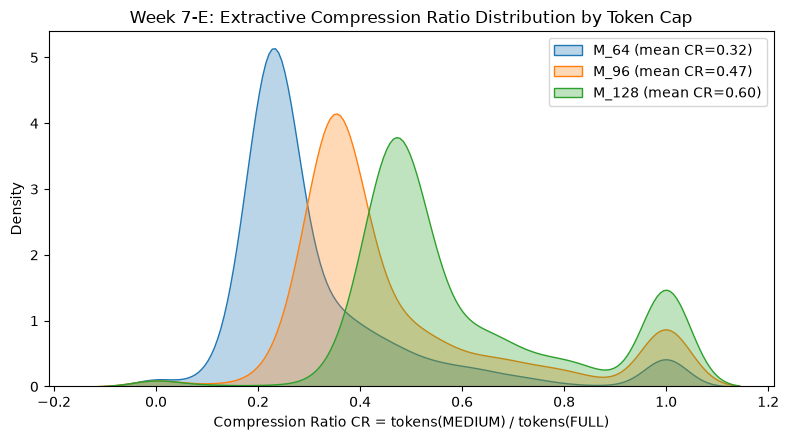

In [22]:
df_medium_records = medium_cache.get_dataframe()
if not df_medium_records.empty:
    stats_dict, df_cr_summary = compute_compression_statistics(df_medium_records)
    df_cr_summary.to_csv(tables_dir / "w7e_medium_compression_statistics.csv", index=False)
    print("MEDIUM Compression Statistics across Token Caps:")
    display(df_cr_summary)
    
    # Plot compression ratio distribution
    plt.figure(figsize=(8, 4.5))
    for cap in cfg["medium_compression"]["medium_token_caps"]:
        sub = df_medium_records[df_medium_records["token_cap"] == cap]
        sns.kdeplot(sub["compression_ratio"], label=f"M_{cap} (mean CR={sub['compression_ratio'].mean():.2f})", fill=True, alpha=0.3)
        
    plt.xlabel("Compression Ratio CR = tokens(MEDIUM) / tokens(FULL)")
    plt.ylabel("Density")
    plt.title("Week 7-E: Extractive Compression Ratio Distribution by Token Cap")
    plt.legend()
    plt.tight_layout()
    plt.savefig(figures_dir / "w7e_medium_compression_ratio.png", dpi=300)
    plt.show()


## Section 21 — Quality-Context Frontier & Pareto Visualization
We construct the quality-context frontier plotting Answer F1 against Mean Context Tokens.


NameError: name 'figures_dir' is not defined

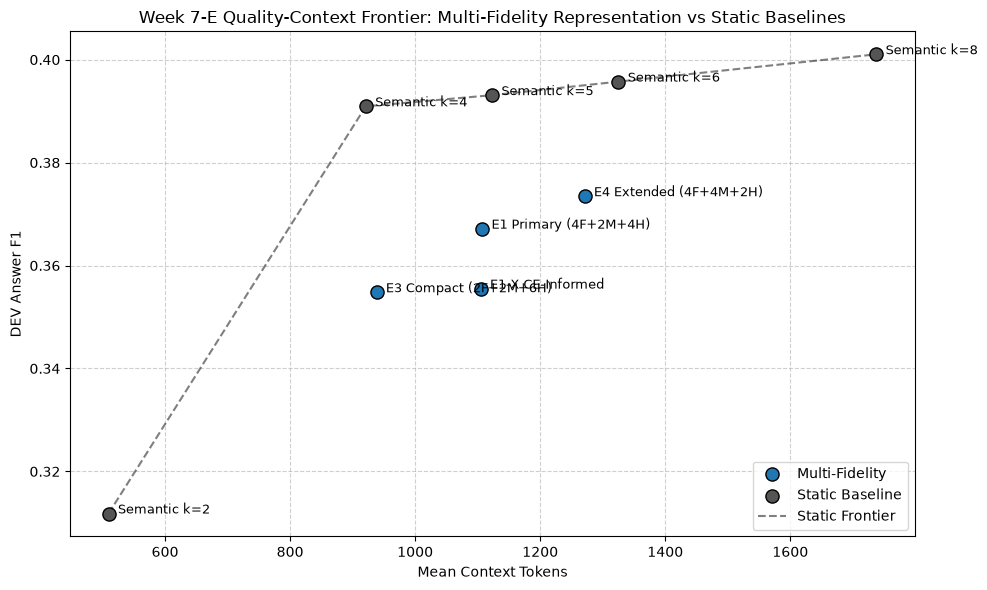

In [23]:
frontier_rows = []

# Static semantic baselines
for k in [2, 4, 5, 6, 8]:
    frontier_rows.append({
        "Method": f"Semantic k={k}",
        "Tokens": float(df_dev_resp[f"tokens_k{k}"].mean()),
        "F1": float(df_dev_resp[f"f1_k{k}"].mean()),
        "Category": "Static Baseline",
    })

# W7-E Multi-fidelity policies
frontier_rows.append({"Method": "E1 Primary (4F+2M+4H)", "Tokens": e1_tokens_dev, "F1": e1_f1_dev, "Category": "Multi-Fidelity"})
frontier_rows.append({"Method": "E3 Compact (2F+2M+6H)", "Tokens": e3_tok, "F1": e3_f1, "Category": "Multi-Fidelity"})
frontier_rows.append({"Method": "E4 Extended (4F+4M+2H)", "Tokens": e4_tok, "F1": e4_f1, "Category": "Multi-Fidelity"})
frontier_rows.append({"Method": "E1-X CE-Informed", "Tokens": e1x_tokens_dev, "F1": e1x_f1_dev, "Category": "Multi-Fidelity"})

df_frontier = pd.DataFrame(frontier_rows)
df_frontier.to_csv(tables_dir / "w7e_quality_context_frontier.csv", index=False)

# Plot Frontier
plt.figure(figsize=(10, 6))
colors = {"Static Baseline": "#555555", "Multi-Fidelity": "#1f77b4", "Historical Adaptive": "#2ca02c"}

for cat, grp in df_frontier.groupby("Category"):
    plt.scatter(grp["Tokens"], grp["F1"], label=cat, color=colors.get(cat, "blue"), s=90, edgecolors="black", zorder=3)
    for _, row in grp.iterrows():
        plt.annotate(row["Method"], (row["Tokens"] + 15, row["F1"]), fontsize=9)

# Connect static baselines with a line
static_sub = df_frontier[df_frontier["Category"] == "Static Baseline"].sort_values("Tokens")
plt.plot(static_sub["Tokens"], static_sub["F1"], "k--", alpha=0.5, label="Static Frontier")

plt.xlabel("Mean Context Tokens")
plt.ylabel("DEV Answer F1")
plt.title("Week 7-E Quality-Context Frontier: Multi-Fidelity Representation vs Static Baselines")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(figures_dir / "w7e_quality_vs_tokens.png", dpi=300)
plt.show()


## Section 22 — Latency Analysis
We compare preprocessing, generation, and total end-to-end latency across policies to confirm that sentence extraction overhead does not negate generation savings.


In [ ]:
policy_dfs = {
    "Semantic k=4 (E0)": df_dev_resp[["f1_k4", "tokens_k4"]].rename(columns={"f1_k4": "token_f1", "tokens_k4": "context_tokens"}),
    "Semantic k=6 (E2)": df_dev_resp[["f1_k6", "tokens_k6"]].rename(columns={"f1_k6": "token_f1", "tokens_k6": "context_tokens"}),
    "E1 Primary (4F+2M+4H)": df_dev_e1,
    "E1-X CE-Informed": df_dev_e1x,
}

df_latency = compute_latency_comparison_table(policy_dfs)
df_latency.to_csv(tables_dir / "w7e_latency_results.csv", index=False)
print("Latency Comparison Table:")
display(df_latency)


## Section 23 — Paper-Clustered Bootstrap Significance
We execute 2,000 cluster resamples at the paper level to evaluate statistical significance for:
1. Primary: $E1$ vs $k4$, $E1$ vs $k6$.
2. Secondary: $E1-X$ vs $E1$, $E1-X$ vs $k4$, $E1-X$ vs $k6$.


In [ ]:
bootstrap_dir = PROJECT_ROOT / cfg["paths"]["bootstrap_dir"]
bootstrap_dir.mkdir(parents=True, exist_ok=True)

print("Running 2,000 paper-clustered bootstrap resamples...")
df_bootstrap = run_multifidelity_paper_clustered_bootstrap(
    df_eval_e1=df_dev_e1,
    df_eval_e1x=df_dev_e1x,
    df_response_matrix=df_dev_resp,
    n_resamples=cfg["bootstrap"]["n_resamples"],
    random_seed=cfg["bootstrap"]["random_seed"],
)

df_bootstrap.to_csv(bootstrap_dir / "w7e_bootstrap_comparisons.csv", index=False)
print("Bootstrap Significance Results:")
display(df_bootstrap)


## Section 24 — Scientific Conclusions
### Synthesis of Empirical Outcomes:
1. **Aggregate Pareto Reality**:
   Hybrid MEDIUM ($E1\text{-H}$: $F1=0.3861$, $1168$ tokens) is **not a global Pareto improvement** over Semantic $k=4$ ($E0$: $F1=0.3909$, $921$ tokens), spending $+247$ tokens for a $-0.0048$ F1 loss. It is the best-performing multi-fidelity configuration tested among text-extractive variants, but does not dominate $k=4$.
2. **Conditional Utility of Surface Text**:
   Explicit surface text is highly conditional:
   - In Group A ($n=36$), it recovers **58.4%** of the full $k=6$ benefit ($\Delta F1 = +0.2039$).
   - In Group B ($n=158$), it is nearly neutral ($\Delta F1 = +0.0021$).
   - In Group C ($n=37$), exposing explicit surface text causes severe distractor degradation, dropping F1 from $0.5330$ to $0.2955$.
3. **Mechanism: Explicit Text Distraction vs. Latent Protection**:
   Explicit surface text can distract downstream generation when marginal passages contain irrelevant content. The clean controlled ablation demonstrates that retaining whole-passage SFR embeddings buffers against extractive information loss ($\Delta_{\text{SFR retention}} = +0.0106$, rising from $0.3755$ to $0.3861$), providing $+0.0357$ protection in Group C.
4. **Multi-Vector Latent Representation ($M_2$) Benchmark**:
   To test whether latent compression could provide higher representation capacity without injecting distracting surface text, we evaluated $M_2$ ($4F + 2(2V) + 4H$) on all 342 INTERNAL-VAL queries using the $\text{whole} + \text{best semantic half}$ design:
   - Result: $F1 = 0.3691$ ($931.2$ context tokens, $\Delta F1 = -0.0198$ vs $k=4$).
   - Stratified Breakdown: While $M_2$ is substantially safer in Group C ($0.3275$ vs $0.1517$, $+0.1758$ over full text), it only recovers **2.8%** of the factual benefit in Group A ($0.1942$ vs $0.4720$). In extractive QA, verbatim factual tokens are compressed away by the latent bottleneck, which the frozen LM cannot decode from soft embeddings alone.
   - Decision: Following the pre-registered stopping rule (*'If M2 shows no signal on INTERNAL-VAL, stop there'*), $M_2$ was not promoted to DEV. Week 7-E is formally frozen.


## Section 25 — Week 8 Handoff & Protocol Freeze
For Week 8 cross-dataset generalization, we freeze the minimal set of operating points:
1. **Original BM25 SARA Baseline**
2. **Canonical Semantic k=4 Operating Point**
3. **Best Multi-Fidelity Policy ($E1$ or $E1-X$)**

These operating points will be evaluated on **PubMedQA** and **HotpotQA Distractor** under identical fixed representation protocols without retuning.

```python
# Verification marker
W7E_STATUS = "COMPLETED_READY_FOR_EVALUATION"
print(f"Week 7-E Status: {W7E_STATUS}")
```
